In [9]:
import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense, Conv2D, Flatten, MaxPooling2D
from data_loader import target_dir as DATA_DIR
import matplotlib.pyplot as plt


In [4]:
import tensorflow as tf

def build_cnn_model():
    cnn_model = tf.keras.Sequential([
        # Entrée + Normalisation [0, 255] -> [0, 1]
        tf.keras.layers.Input(shape=(224, 224, 3)),
        tf.keras.layers.Rescaling(1./255),

        # Bloc 1
        tf.keras.layers.Conv2D(filters=32, kernel_size=(3,3), padding='same', kernel_initializer='he_uniform', activation=tf.nn.relu),
        tf.keras.layers.MaxPool2D(pool_size=(2,2), strides=2),

        # Bloc 2
        tf.keras.layers.Conv2D(filters=64, kernel_size=(3,3), padding='same', kernel_initializer='he_uniform', activation=tf.nn.relu),
        tf.keras.layers.MaxPool2D(pool_size=(2,2), strides=2),

        # Bloc 3 (ajouté pour réduire la taille et capter des formes plus complexes)
        tf.keras.layers.Conv2D(filters=128, kernel_size=(3,3), padding='same', kernel_initializer='he_uniform', activation=tf.nn.relu),
        tf.keras.layers.MaxPool2D(pool_size=(2,2), strides=2),

        # Classification (GlobalAveragePooling2D évite les 24 millions de paramètres)
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.4),
        tf.keras.layers.Dense(128, activation=tf.nn.relu, kernel_initializer='he_uniform'),
        tf.keras.layers.Dense(10, activation=tf.nn.softmax)
    ])

    return cnn_model

cnn_model = build_cnn_model()
cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
cnn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [8]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "valid",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop]
)

Found 1468 files belonging to 10 classes.
Found 50 files belonging to 10 classes.
Found 50 files belonging to 10 classes.
Epoch 1/15


c:\Users\valen\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


46/46 ━━━━━━━━━━━━━━━━━━━━ 21s 395ms/step - accuracy: 0.1751 - loss: 2.2525 - val_accuracy: 0.2800 - val_loss: 1.9701
Epoch 2/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 25s 540ms/step - accuracy: 0.2657 - loss: 1.9288 - val_accuracy: 0.3800 - val_loss: 1.7621
Epoch 3/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 23s 501ms/step - accuracy: 0.3147 - loss: 1.7991 - val_accuracy: 0.3600 - val_loss: 1.6368
Epoch 4/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 24s 522ms/step - accuracy: 0.3842 - loss: 1.6761 - val_accuracy: 0.4200 - val_loss: 1.5242
Epoch 5/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 26s 571ms/step - accuracy: 0.4101 - loss: 1.5863 - val_accuracy: 0.4600 - val_loss: 1.4561
Epoch 6/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 28s 620ms/step - accuracy: 0.4700 - loss: 1.4500 - val_accuracy: 0.6400 - val_loss: 1.2522
Epoch 7/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 29s 631ms/step - accuracy: 0.5020 - loss: 1.3964 - val_accuracy: 0.5800 - val_loss: 1.1781
Epoch 8/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 31s 679ms/step - accuracy: 0.5232 - loss: 1.3285 - val_accuracy: 0.680

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.7600 - loss: 0.8944
Précision finale sur le test : 76.00%


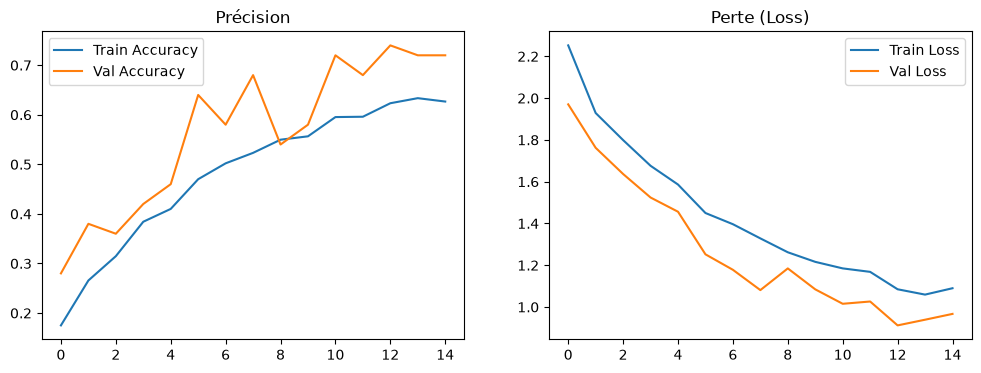

In [10]:
test_loss, test_acc = cnn_model.evaluate(test_ds)
print(f"Précision finale sur le test : {test_acc:.2%}")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Précision')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Perte (Loss)')
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step


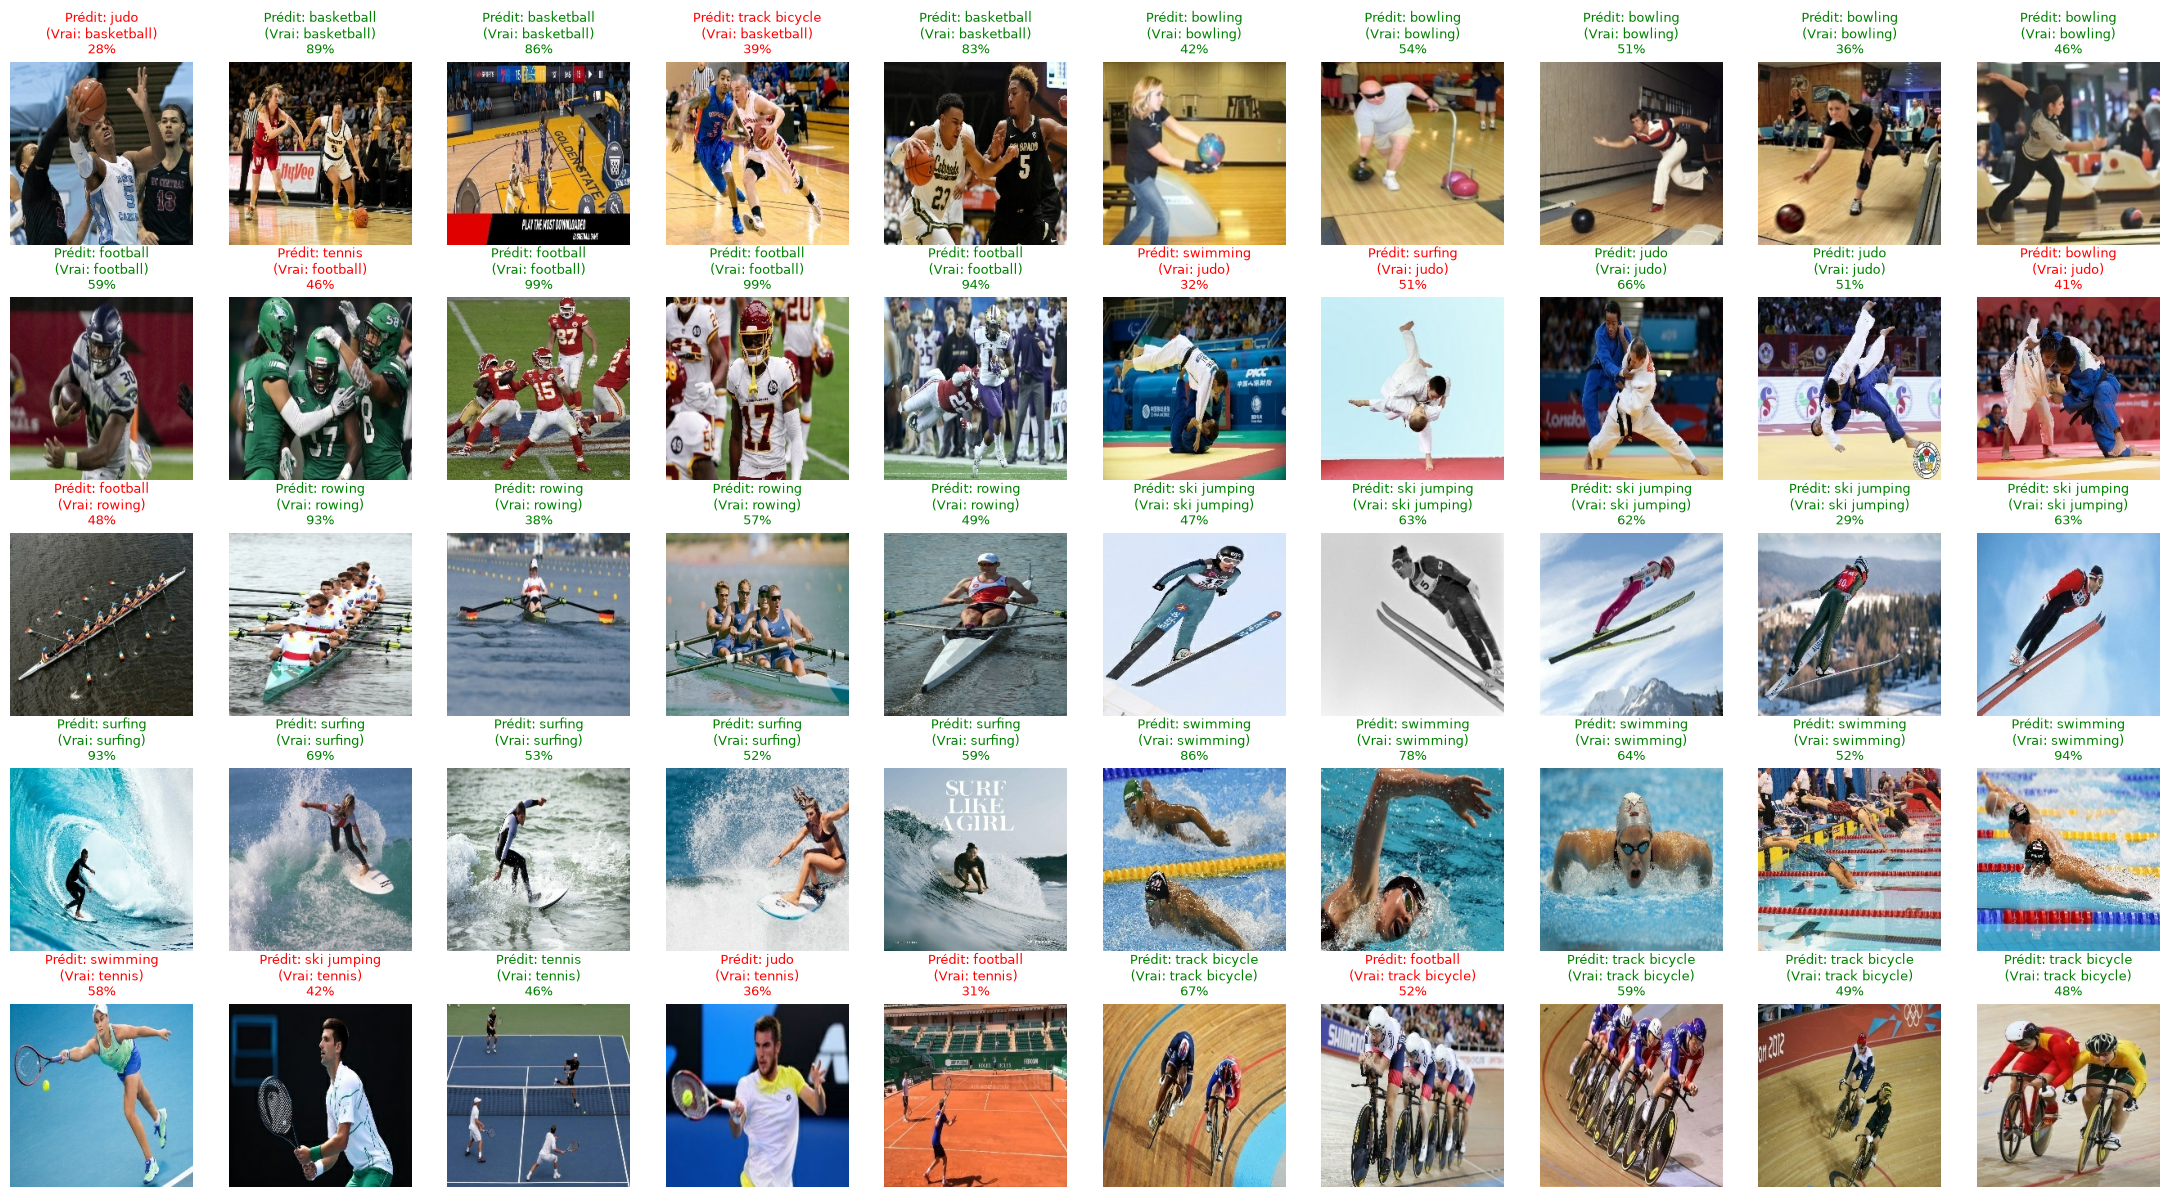

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Récupérer les noms des 10 classes (dans l'ordre alphabétique de Keras)
class_names = test_ds.class_names

# 2. Prédire sur tout le jeu de test
predictions = cnn_model.predict(test_ds)
predicted_indices = np.argmax(predictions, axis=1)
confidences = np.max(predictions, axis=1)

# 3. Extraire toutes les images et les vraies étiquettes depuis test_ds
test_images = np.concatenate([images.numpy() for images, _ in test_ds], axis=0)
true_indices = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0)

# 4. Afficher les 50 images dans une grille (5 lignes x 10 colonnes)
fig, axes = plt.subplots(5, 10, figsize=(22, 12))
axes = axes.flatten()

for i in range(len(test_images)):
    ax = axes[i]
    # .astype("uint8") est nécessaire car image_dataset_from_directory charge les pixels en float32 [0, 255]
    ax.imshow(test_images[i].astype("uint8"))
    
    pred_label = class_names[predicted_indices[i]]
    true_label = class_names[true_indices[i]]
    conf = confidences[i] * 100
    
    is_correct = (predicted_indices[i] == true_indices[i])
    color = "green" if is_correct else "red"
    
    ax.set_title(f"Prédit: {pred_label}\n(Vrai: {true_label})\n{conf:.0f}%", color=color, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()